In [26]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

import cartopy.crs as ccrs
from nese.verify.maps import draw_cells

In [2]:
from importlib.resources import files
plt.style.use(files("nese.verify") / "nese.mplstyle")

In [7]:
ds

<xarray.Dataset> Size: 6GB
Dimensions:                                        (t0: 363, cell: 33416)
Coordinates:
  * t0                                             (t0) datetime64[ns] 3kB 20...
    valid_time                                     (t0) datetime64[ns] 3kB dask.array<chunksize=(363,), meta=np.ndarray>
  * cell                                           (cell) int64 267kB 0 ... 4...
    latitude                                       (cell) float64 267kB dask.array<chunksize=(16708,), meta=np.ndarray>
    longitude                                      (cell) float64 267kB dask.array<chunksize=(16708,), meta=np.ndarray>
    fhr                                            int64 8B 24
    lead_time                                      timedelta64[ns] 8B dask.array<chunksize=(), meta=np.ndarray>
Data variables: (12/118)
    elevation                                      (t0, cell) float32 49MB dask.array<chunksize=(1, 33416), meta=np.ndarray>
    land_fraction                                  (t0, cell) float32 49MB dask.array<chunksize=(1, 33416), meta=np.ndarray>
    mdt                                            (t0, cell) float32 49MB dask.array<chunksize=(1, 33416), meta=np.ndarray>
    mdt_u                                          (t0, cell) float32 49MB dask.array<chunksize=(1, 33416), meta=np.ndarray>
    mdt_v                                          (t0, cell) float32 49MB dask.array<chunksize=(1, 33416), meta=np.ndarray>
    sla                                            (t0, cell) float32 49MB dask.array<chunksize=(1, 33416), meta=np.ndarray>
    ...                                             ...
    vgxt_saral                                     (t0, cell) float32 49MB dask.array<chunksize=(1, 33416), meta=np.ndarray>
    vgxt_saral_geodetic                            (t0, cell) float32 49MB dask.array<chunksize=(1, 33416), meta=np.ndarray>
    vgxt_sentinel_3a                               (t0, cell) float32 49MB dask.array<chunksize=(1, 33416), meta=np.ndarray>
    vgxt_sentinel_3b                               (t0, cell) float32 49MB dask.array<chunksize=(1, 33416), meta=np.ndarray>
    vgxt_topex_poseidon                            (t0, cell) float32 49MB dask.array<chunksize=(1, 33416), meta=np.ndarray>
    vgxt_topex_poseidon_interleaved                (t0, cell) float32 49MB dask.array<chunksize=(1, 33416), meta=np.ndarray>
Attributes: (12/29)
    cell_selection:          gebco.land_fraction < 0.1 & cmems_mdt.mdt notnul...
    checkpoint:              /cluster/projects/nn2993k/timith/nese/experiment...
    data_frequency:          24h
    dataset_name:            ocean
    field_shape:             [33416]
    healpix_cells_selected:  33416
    ...                      ...
    timestep:                24h
    training_dataset_attrs:  {'allow_nans': True, 'binned': True, 'cell_selec...
    training_timestamp:      2026-10-07T12:16:46.742231+00:00
    uuid:                    fe9f4f40-1c67-4409-9b42-096829ee85b4
    variables:               ['cos_julian_day', 'cos_latitude', 'cos_longitud...
    variables_metadata:      {'cos_julian_day': {'computed_forcing': True, 'c...

In [5]:
ds = xr.open_zarr("runs/v4/inference-2015/forecast.zarr/")
ds = ds.isel(fhr=1)

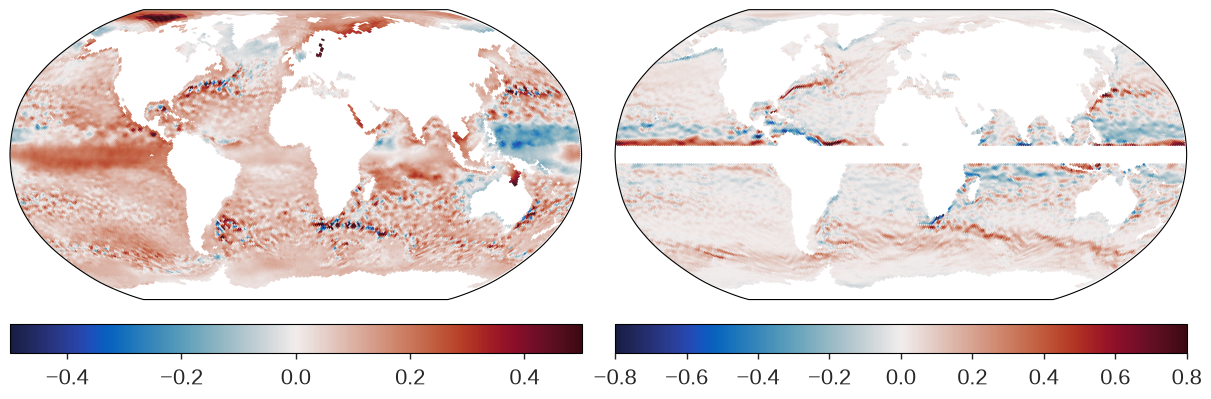

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), subplot_kw={"projection":ccrs.Robinson()})

vmax = {
    "sla": .5,
    "ugxt": .8,
}

for fieldname, ax in zip(["sla", "ugxt"], axs): 
    p = draw_cells(
        ax,
        ds[fieldname].isel(t0=-1),
        ds.attrs,
        vmax=vmax[fieldname],
        vmin=-vmax[fieldname],
        cmap="cmo.balance",
    )
    plt.colorbar(p, ax=ax, orientation="horizontal")
fig

In [29]:
n_u = ds["ugxt"].isel(t0=0).isnull().sum().values
n_v = ds["vgxt"].isel(t0=0).isnull().sum().values
n_s = ds["sla"].isel(t0=0).isnull().sum().values

In [30]:
n_u

array(3331)

In [31]:
n_v

array(3331)

In [32]:
n_s

array(0)

In [34]:
1 - n_u / len(ds.cell)

np.float64(0.9003172133109888)